Adding the first code cell

In [2]:

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

# Project paths
PROJECT_ROOT = Path.cwd().parent
DATA_ROOT = PROJECT_ROOT / "data" / "raw" / "mvtec-ad" / "bottle"
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Use Apple's Metal GPU when available
DEVICE = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

# Image settings
IMAGE_SIZE = 128
BATCH_SIZE = 16

print("Device:", DEVICE)
print("Training images:", DATA_ROOT / "train" / "good")
print("Model output directory:", MODEL_DIR)


Device: mps
Training images: /Users/anupamguptaroy17/Projects/VisionQC/data/raw/mvtec-ad/bottle/train/good
Model output directory: /Users/anupamguptaroy17/Projects/VisionQC/models


Creating the Training Dataset Loader

In [2]:

class BottleDataset(Dataset):
    """Loads normal bottle images for autoencoder training."""

    def __init__(self, image_dir, image_size=128):
        self.image_paths = sorted(Path(image_dir).glob("*.png"))

        self.transform = transforms.Compose([
            transforms.Resize((image_size, image_size)),
            transforms.ToTensor(),
        ])

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image_path = self.image_paths[index]

        with Image.open(image_path) as image:
            image = image.convert("RGB")
            image = self.transform(image)

        # The autoencoder will learn to reconstruct this same image.
        return image


train_dataset = BottleDataset(
    DATA_ROOT / "train" / "good",
    image_size=IMAGE_SIZE,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
)

print("Training images loaded:", len(train_dataset))
print("Number of batches:", len(train_loader))

# Inspect one batch
sample_batch = next(iter(train_loader))
print("Batch shape:", sample_batch.shape)
print("Pixel range:", sample_batch.min().item(), "to", sample_batch.max().item())


Training images loaded: 209
Number of batches: 14
Batch shape: torch.Size([16, 3, 128, 128])
Pixel range: 0.11764705926179886 to 1.0


Building the autoencoder model

In [3]:

class BottleAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        # Encoder: progressively compress the image.
        self.enc1 = nn.Sequential(
            nn.Conv2d(3, 16, 3, 2, 1),
            nn.ReLU(inplace=True)
        )

        self.enc2 = nn.Sequential(
            nn.Conv2d(16, 32, 3, 2, 1),
            nn.ReLU(inplace=True)
        )

        self.enc3 = nn.Sequential(
            nn.Conv2d(32, 64, 3, 2, 1),
            nn.ReLU(inplace=True)
        )

        self.enc4 = nn.Sequential(
            nn.Conv2d(64, 128, 3, 2, 1),
            nn.ReLU(inplace=True)
        )

        # Decoder: reconstruct the image using skip connections.
        self.up3 = nn.ConvTranspose2d(128, 64, 4, 2, 1)
        self.dec3 = nn.Sequential(
            nn.Conv2d(128, 64, 3, 1, 1),
            nn.ReLU(inplace=True)
        )

        self.up2 = nn.ConvTranspose2d(64, 32, 4, 2, 1)
        self.dec2 = nn.Sequential(
            nn.Conv2d(64, 32, 3, 1, 1),
            nn.ReLU(inplace=True)
        )

        self.up1 = nn.ConvTranspose2d(32, 16, 4, 2, 1)
        self.dec1 = nn.Sequential(
            nn.Conv2d(32, 16, 3, 1, 1),
            nn.ReLU(inplace=True)
        )

        self.up0 = nn.ConvTranspose2d(16, 3, 4, 2, 1)
        self.output_activation = nn.Sigmoid()

    def forward(self, x):
        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(e1)
        e3 = self.enc3(e2)
        e4 = self.enc4(e3)

        # Decoder with skip connections
        d3 = self.up3(e4)
        d3 = torch.cat([d3, e3], dim=1)
        d3 = self.dec3(d3)

        d2 = self.up2(d3)
        d2 = torch.cat([d2, e2], dim=1)
        d2 = self.dec2(d2)

        d1 = self.up1(d2)
        d1 = torch.cat([d1, e1], dim=1)
        d1 = self.dec1(d1)

        output = self.up0(d1)

        return self.output_activation(output)


Testing the Architecture

In [4]:
model = BottleAutoencoder().to(DEVICE)

sample_input = torch.randn(1, 3, IMAGE_SIZE, IMAGE_SIZE).to(DEVICE)

with torch.no_grad():
    sample_output = model(sample_input)

print("Device:", next(model.parameters()).device)
print("Input shape:", sample_input.shape)
print("Output shape:", sample_output.shape)
print("Trainable parameters:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

Device: mps:0
Input shape: torch.Size([1, 3, 128, 128])
Output shape: torch.Size([1, 3, 128, 128])
Trainable parameters: 367235


Configuring the training process

In [5]:

# Loss function: measures the difference between original
# and reconstructed bottle images.
criterion = nn.MSELoss()

# Adam optimiser updates the model's weights during training.
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

# Number of complete passes through the training dataset.
NUM_EPOCHS = 30

print("Loss function:", criterion)
print("Optimiser:", optimizer.__class__.__name__)
print("Learning rate:", optimizer.param_groups[0]["lr"])
print("Epochs:", NUM_EPOCHS)
print("Device:", DEVICE)


Loss function: MSELoss()
Optimiser: Adam
Learning rate: 0.001
Epochs: 30
Device: mps


Dataset and Dataloader

In [7]:

from torch.utils.data import Dataset, DataLoader
from pathlib import Path
from PIL import Image
from torchvision import transforms

# Dataset location
DATA_ROOT = PROJECT_ROOT / "data" / "raw" / "mvtec-ad" / "bottle"

# Image preprocessing (same resolution as baseline).
transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor()
])

# Dataset containing only normal training images.
class BottleDataset(Dataset):
    def __init__(self, image_dir, transform=None):
        self.image_paths = sorted(Path(image_dir).glob("*.png"))
        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image_path = self.image_paths[index]

        with Image.open(image_path) as image:
            image = image.convert("RGB")

            if self.transform:
                image = self.transform(image)

        return image


# Load normal bottle images.
train_dataset = BottleDataset(
    DATA_ROOT / "train" / "good",
    transform=transform
)

# Create batches for training.
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

print("Training images:", len(train_dataset))
print("Number of batches:", len(train_loader))
print("Batch size:", BATCH_SIZE)

# Verify the data shape.
sample_batch = next(iter(train_loader))
print("Batch shape:", sample_batch.shape)


Training images: 209
Number of batches: 14
Batch size: 16
Batch shape: torch.Size([16, 3, 128, 128])


Train the autoencoder

In [8]:

# Store the average reconstruction loss for each epoch.
epoch_losses = []

model.train()

for epoch in range(NUM_EPOCHS):
    running_loss = 0.0

    for images in train_loader:
        images = images.to(DEVICE)

        # Clear gradients from the previous batch.
        optimizer.zero_grad()

        # Reconstruct the input images.
        reconstructed = model(images)

        # Compare reconstructed images against original images.
        loss = criterion(reconstructed, images)

        # Calculate gradients and update model weights.
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    # Average loss across the entire training dataset.
    epoch_loss = running_loss / len(train_dataset)
    epoch_losses.append(epoch_loss)

    print(
        f"Epoch [{epoch + 1:02d}/{NUM_EPOCHS}] "
        f"Loss: {epoch_loss:.6f}"
    )

print("\nSkip-connection training complete!")
print(f"Final training loss: {epoch_losses[-1]:.6f}")

# Save the trained model separately.
MODEL_PATH = PROJECT_ROOT / "models" / "bottle_autoencoder_skip.pth"

torch.save(model.state_dict(), MODEL_PATH)

print(f"Model saved to: {MODEL_PATH}")


Epoch [01/30] Loss: 0.125609
Epoch [02/30] Loss: 0.064872
Epoch [03/30] Loss: 0.027899
Epoch [04/30] Loss: 0.012083
Epoch [05/30] Loss: 0.006155
Epoch [06/30] Loss: 0.004727
Epoch [07/30] Loss: 0.004135
Epoch [08/30] Loss: 0.003709
Epoch [09/30] Loss: 0.003475
Epoch [10/30] Loss: 0.003128
Epoch [11/30] Loss: 0.003034
Epoch [12/30] Loss: 0.002641
Epoch [13/30] Loss: 0.002460
Epoch [14/30] Loss: 0.002299
Epoch [15/30] Loss: 0.002150
Epoch [16/30] Loss: 0.002086
Epoch [17/30] Loss: 0.002118
Epoch [18/30] Loss: 0.001913
Epoch [19/30] Loss: 0.001854
Epoch [20/30] Loss: 0.001833
Epoch [21/30] Loss: 0.001884
Epoch [22/30] Loss: 0.001802
Epoch [23/30] Loss: 0.001696
Epoch [24/30] Loss: 0.001643
Epoch [25/30] Loss: 0.001625
Epoch [26/30] Loss: 0.001565
Epoch [27/30] Loss: 0.001568
Epoch [28/30] Loss: 0.001531
Epoch [29/30] Loss: 0.001478
Epoch [30/30] Loss: 0.001451

Skip-connection training complete!
Final training loss: 0.001451
Model saved to: /Users/anupamguptaroy17/Projects/VisionQC/models

In [10]:
def load_image_tensor(path):
    with Image.open(path) as image:
        image = image.convert("RGB")
        image = transforms.Resize((IMAGE_SIZE, IMAGE_SIZE))(image)
        return transforms.ToTensor()(image)

Visualising the reconstruction

Reconstruction MSE: 0.001419


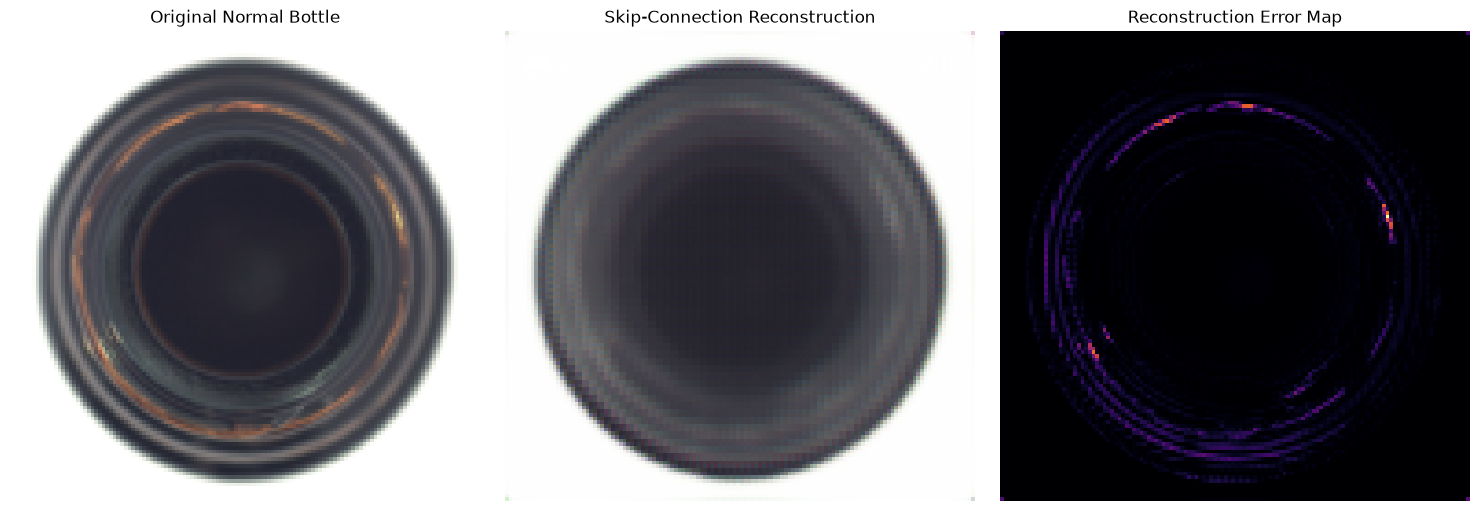

In [11]:

# Load a normal bottle image.
normal_path = DATA_ROOT / "test" / "good" / "000.png"

normal_tensor = load_image_tensor(normal_path).unsqueeze(0).to(DEVICE)

model.eval()

with torch.no_grad():
    normal_reconstruction = model(normal_tensor)

original_array = (
    normal_tensor[0].cpu().permute(1, 2, 0).numpy()
)

reconstructed_array = (
    normal_reconstruction[0].cpu().permute(1, 2, 0).numpy()
)

error_map = np.mean(
    (original_array - reconstructed_array) ** 2,
    axis=2
)

print(f"Reconstruction MSE: {error_map.mean():.6f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(original_array)
axes[0].set_title("Original Normal Bottle")
axes[0].axis("off")

axes[1].imshow(reconstructed_array)
axes[1].set_title("Skip-Connection Reconstruction")
axes[1].axis("off")

axes[2].imshow(error_map, cmap="inferno")
axes[2].set_title("Reconstruction Error Map")
axes[2].axis("off")

plt.tight_layout()
plt.show()


Evaluating all 83 Images with Skip connection method

In [12]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
)

# 1. Load images at the correct resolution (128x128).
def load_image_tensor(path):
    with Image.open(path) as image:
        image = image.convert("RGB")
        image = transforms.Resize((IMAGE_SIZE, IMAGE_SIZE))(image)
        return transforms.ToTensor()(image)


# 2. Calculate the pixel-wise reconstruction error map.
def get_reconstruction(image_tensor):
    model.eval()

    with torch.no_grad():
        image_tensor = image_tensor.to(DEVICE)
        reconstruction = model(image_tensor)
        error_map = (image_tensor - reconstruction).pow(2).mean(dim=1)

    return error_map[0].cpu().numpy()


model.eval()

# 3. Calibrate a provisional threshold using normal training images.
train_scores = []

for path in sorted((DATA_ROOT / "train" / "good").glob("*.png")):
    tensor = load_image_tensor(path).unsqueeze(0)
    error_map = get_reconstruction(tensor)
    train_scores.append(float(error_map.mean()))

threshold = float(np.percentile(train_scores, 99))

print(f"Image resolution: {IMAGE_SIZE}x{IMAGE_SIZE}")
print(f"Provisional anomaly threshold: {threshold:.6f}")

# 4. Evaluate all test images.
true_labels = []
predicted_labels = []
image_scores = []
pixel_errors = []
pixel_labels = []

for category in sorted(
    p.name for p in (DATA_ROOT / "test").iterdir() if p.is_dir()
):
    for path in sorted((DATA_ROOT / "test" / category).glob("*.png")):
        is_defective = category != "good"

        tensor = load_image_tensor(path).unsqueeze(0)
        error_map = get_reconstruction(tensor)
        score = float(error_map.mean())

        true_labels.append(int(is_defective))
        predicted_labels.append(int(score > threshold))
        image_scores.append(score)

        # Load the ground-truth defect mask.
        if is_defective:
            mask_path = (
                DATA_ROOT / "ground_truth" / category
                / f"{path.stem}_mask.png"
            )

            with Image.open(mask_path) as mask_image:
                mask_image = mask_image.convert("L").resize(
                    (IMAGE_SIZE, IMAGE_SIZE),
                    Image.Resampling.NEAREST,
                )
                mask = np.asarray(mask_image) > 0
        else:
            mask = np.zeros(
                (IMAGE_SIZE, IMAGE_SIZE), dtype=bool
            )

        pixel_errors.extend(error_map.ravel())
        pixel_labels.extend(mask.ravel())

# 5. Report image-level detection metrics.
print("\nIMAGE-LEVEL RESULTS")
print("Test images:", len(true_labels))
print(f"Accuracy:  {accuracy_score(true_labels, predicted_labels):.3f}")
print(f"Precision: {precision_score(true_labels, predicted_labels, zero_division=0):.3f}")
print(f"Recall:    {recall_score(true_labels, predicted_labels, zero_division=0):.3f}")
print(f"F1 score:  {f1_score(true_labels, predicted_labels, zero_division=0):.3f}")
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(confusion_matrix(true_labels, predicted_labels))

# 6. Report pixel-level localisation performance.
print("\nLOCALISATION RESULTS")

try:
    pixel_auc = roc_auc_score(pixel_labels, pixel_errors)
    print(f"Pixel-level ROC-AUC: {pixel_auc:.3f}")
except ValueError:
    print("Pixel-level ROC-AUC could not be calculated.")

print("\nEvaluation complete.")


Image resolution: 128x128
Provisional anomaly threshold: 0.001861

IMAGE-LEVEL RESULTS
Test images: 83
Accuracy:  0.530
Precision: 0.900
Recall:    0.429
F1 score:  0.581
Confusion matrix [[TN, FP], [FN, TP]]:
[[17  3]
 [36 27]]

LOCALISATION RESULTS
Pixel-level ROC-AUC: 0.697

Evaluation complete.


Comparing different thresolds

In [10]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

thresholds = [
    threshold * 0.50,
    threshold * 0.65,
    threshold * 0.80,
    threshold,
    threshold * 1.20,
]

print(f"{'Threshold':>12} {'Accuracy':>10} {'Precision':>10} "
      f"{'Recall':>10} {'F1':>10} {'False alarms':>14} {'Missed defects':>15}")

for t in thresholds:
    predictions = (np.array(image_scores) > t).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        true_labels, predictions, labels=[0, 1]
    ).ravel()

    print(
        f"{t:12.6f} "
        f"{accuracy_score(true_labels, predictions):10.3f} "
        f"{precision_score(true_labels, predictions, zero_division=0):10.3f} "
        f"{recall_score(true_labels, predictions, zero_division=0):10.3f} "
        f"{f1_score(true_labels, predictions, zero_division=0):10.3f} "
        f"{fp:14d} {fn:15d}"
    )


   Threshold   Accuracy  Precision     Recall         F1   False alarms  Missed defects
    0.001327      0.759      0.759      1.000      0.863             20               0
    0.001725      0.759      0.759      1.000      0.863             20               0
    0.002123      0.771      0.814      0.905      0.857             13               6
    0.002653      0.651      0.947      0.571      0.713              2              27
    0.003184      0.506      1.000      0.349      0.518              0              41
